# 0 · Where virtual cells stand, and what this project builds

This notebook is the map. It records what earlier whole-cell efforts achieved, **why each worked**, where each
stops, and the design decisions this project draws from them. The remaining notebooks build and test the model.

## Three lineages

**1. Mechanistic whole-cell models (1999 → today).** One organism, every known gene function, simulated from
molecular mechanisms.

| Model | Scope | Why it worked | Where it stops |
|---|---|---|---|
| E-Cell (Tomita 1999) | 127-gene hypothetical cell | one rule/ODE engine, tiny system | one formalism cannot fit all processes; parameters unknown |
| *M. genitalium* (Karr 2012) | 525 genes, 28 sub-models | each process in the mathematics its data supports (FBA, stochastic, ODE), coupled through a shared state every second; ~900 papers of curation | smallest genome; >10 person-years; many borrowed parameters |
| *E. coli* (Macklin 2020), Vivarium | 1,214 genes | same modular idea plus systematic cross-checking of data sets | ~43% of the functional genome |
| JCVI-syn3A (Thornburg 2022) | 493 genes, 3-D + time | minimal genome makes full spatial kinetics tractable | relative metabolomics only, proxy kinetics, GPU-heavy |

**2. Human sub-system models.** Genome-scale *stoichiometry* (Recon3D, Human1: 13k reactions, 3.6k genes) and
mechanistic *signalling* (Bouhaddou 2018: 141 genes; Fröhlich 2018; SPARCED 2022). Each is strong alone;
metabolism has no dynamics or regulation, signalling covers <1% of genes, and nobody has joined them into one cell.

**3. AI "virtual cells" (2023 → 2026).** scGPT, GEARS, Arc STATE, Xaira X-Cell, GenBio AIDO Cell. They work
because of scale (tens of millions of perturbed cells). They mostly predict transcriptional responses in a
few cell lines, without conservation laws or mechanism. Ahlmann-Eltze et al. (Nature Methods 2025) showed
deep models did not beat linear baselines, and Arc's own 2025 challenge found hybrids beat pure neural models.

## The gap this project targets

Mechanistic models are complete in **depth** but small in **breadth**; AI models are broad but shallow.
The Karr architecture has never been applied genome-wide to a human cell. This project does that:

* every protein-coding gene is transcribed, translated and degraded stochastically;
* every process uses the formalism its data supports (the Karr/Vivarium principle);
* all parameters come from public measurements, or are inferred by an explicit, recorded rule;
* the model reports its own coverage and gaps (notebook 7).

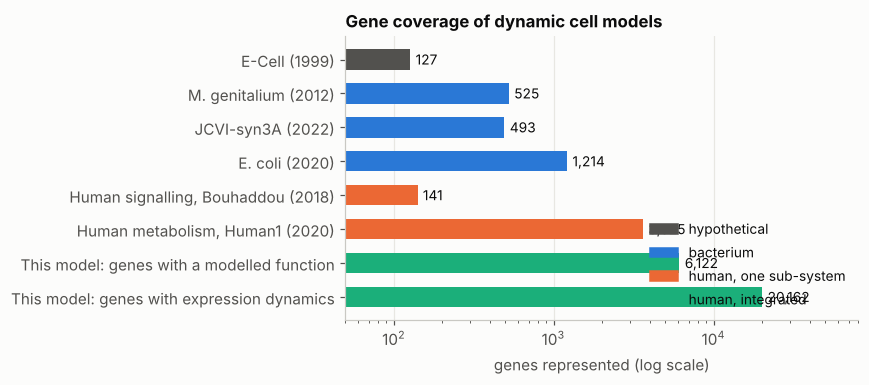

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, matplotlib.pyplot as plt
from humancell import plotting as P; P.style()

models = pd.DataFrame([
    ("E-Cell (1999)", 127, "hypothetical"),
    ("M. genitalium (2012)", 525, "bacterium"),
    ("JCVI-syn3A (2022)", 493, "bacterium"),
    ("E. coli (2020)", 1214, "bacterium"),
    ("Human signalling, Bouhaddou (2018)", 141, "human, one sub-system"),
    ("Human metabolism, Human1 (2020)", 3625, "human, one sub-system"),
    ("This model: genes with a modelled function", 6122, "human, integrated"),
    ("This model: genes with expression dynamics", 20162, "human, integrated"),
], columns=["model", "genes", "kind"])
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {"hypothetical": P.MUTED, "bacterium": P.SERIES[0], "human, one sub-system": P.SERIES[1], "human, integrated": P.SERIES[2]}
ax.barh(models.model, models.genes, color=[colors[k] for k in models.kind], height=0.6)
for y, v in enumerate(models.genes):
    ax.text(v * 1.08, y, f"{v:,}", va="center", color=P.INK, fontsize=9)
ax.set_xscale("log"); ax.set_xlim(50, 80000); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("genes represented (log scale)"); ax.set_title("Gene coverage of dynamic cell models")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], colors.keys(), loc="lower right")
plt.tight_layout(); plt.show()

Breadth is not fidelity. Of the 6,122 genes with a modelled function, most act through genome-scale layers
(stoichiometric metabolism, signed-network signalling) rather than measured kinetics. Notebook 7 breaks this down.

## Architecture

```
                        environment: medium (glucose, O2, amino acids ...), ligands, drugs, radiation
                                                       │
  ┌────────────────────────────────────────────────────┴───────────────────────────────────────────────┐
  │ shared cell state: mRNA and protein copies of 20,162 genes · size · ions · damage · phase · medium │
  └──┬────────────┬─────────────┬──────────────┬──────────────┬───────────────┬──────────────┬─────────┘
  expression   machines     metabolism     signalling     regulation     kinetic modules   cell cycle
  stochastic   Liebig       Human-GEM FBA  OmniPath       CollecTRI      energy, ISR/UPR,  checkpoints,
  birth-death  capacity of  bounded by     signed net,    TF regulons    hypoxia, redox,   replication,
  per gene     ~40 curated  the simulated  5k proteins    1.1k TFs       DNA damage/p53,   division,
               complexes    proteome                                     ions, Ca2+, death lineage
```

## Sources
Karr et al. 2012 *Cell* · Macklin et al. 2020 *Science* · Thornburg et al. 2022 *Cell* · Tomita et al. 1999 ·
Robinson et al. 2020 (Human1) · Bouhaddou et al. 2018 · Fröhlich et al. 2018 · Erdem et al. 2022 (SPARCED) ·
Ahlmann-Eltze et al. 2025 *Nat. Methods* · Arc Institute Virtual Cell Challenge 2025 wrap-up ·
Türei et al. (OmniPath) · Müller-Dott et al. (CollecTRI) · Uhlén et al. (Human Protein Atlas) ·
Schwanhäusser et al. 2011 *Nature* · Hart et al. (CEGv2/NEGv1) · Jost et al. 2020 · Jain et al. 2012.